# 01 · EDA та препроцесинг — VisDrone2019-VID (HW2)

Що покрито (чекпоінт *Data Understanding and Preprocessing*):

| § | Що | Навіщо далі |
|---|----|-------------|
| 1 | Огляд спліту, роздільні здатності train/val/test | вибір `imgsz`, розбіжність train↔test |
| 2 | Класи: загалом і по кліпах | дисбаланс, вибір метрик per-class |
| 3 | Розміри об'єктів: оригінальні px і *після ресайзу* під мережу | `imgsz`, SAHI/тайли, P2-голова |
| 4 | Щільність сцени + перекриття GT між собою | `max_det`, кількість query, поріг NMS |
| 5 | Occlusion / truncation | аналіз помилок |
| 6 | Ignore-регіони: скільки, яку площу, скільки GT під ними | як маскувати |
| 7 | Перевірка конвертації YOLO ↔ COCO + візуалізація | вимога рубрики |
| 8 | Часова кореляція кадрів (через `track_id`) | обґрунтування кроку прорідження |
| 9 | Сплітинг по послідовностях (фолди по кліпах) | валідація без leakage |
| 10 | Якорі: k-means vs дефолтні якорі torchvision | конфіг RetinaNet / Faster R-CNN |
| 11 | Побудова датасету для Ultralytics (виправлена) | вхід для всіх моделей |

Запускається локально на CPU. Шляхи задаються в першій клітинці.

## Налаштування

Структура папок (дані змагання **поза** git-репозиторієм):
```
hw2/
├── train/  val/  test/  test_images.csv     дані змагання
├── build/                                   згенеровані датасети (не в git)
└── solchanyk_hw2/                           git-репозиторій
    ├── report.md, images/
    └── code/notebooks/01_eda_preprocessing.ipynb   ← цей ноутбук
```

In [1]:
from pathlib import Path

DATA_ROOT = Path("../../..").resolve()            # папка з train/ val/ test/
FIG = Path("../../images/eda").resolve()          # графіки для report.md
BUILD = DATA_ROOT / "build"                       # згенеровані датасети

assert (DATA_ROOT / "train" / "annotations_coco.json").exists(), f"Не знайдено train/ у {DATA_ROOT}"
FIG.mkdir(parents=True, exist_ok=True)
print("дані:", DATA_ROOT, "\nграфіки:", FIG)

дані: D:\Vasyl_Solchanyk\3rd year\AI\hw2 
графіки: D:\Vasyl_Solchanyk\3rd year\AI\hw2\solchanyk_hw2\images\eda


In [2]:
import json, random, shutil, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

sys.path.insert(0, str(Path("..").resolve()))     # code/ → бібліотека hw2lib
from hw2lib import PROTOCOL
from hw2lib.data import read_yolo as _read_yolo_px, read_ignore as _read_ignore_px, build_split, write_data_yaml

warnings.filterwarnings("ignore")
SEED = 0
random.seed(SEED); np.random.seed(SEED)
ROOT = DATA_ROOT

NAMES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SPLIT_C = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 0. Завантаження анотацій (COCO) в DataFrame

In [3]:
def load_coco(split, id_offset):
    with open(ROOT / split / "annotations_coco.json", encoding="utf-8") as f:
        d = json.load(f)
    im = pd.DataFrame(d["images"])[["id", "file_name", "video", "frame_id", "width", "height"]]
    im["image_id"] = (im.pop("id") + id_offset).astype(np.int32)   # id у train і val перетинаються
    ann = d.pop("annotations"); del d
    col = lambda k, dt, default=-1: np.array([a.get(k, default) for a in ann], dt)
    bb = np.array([a["bbox"] for a in ann], np.float32)
    an = pd.DataFrame({"image_id": col("image_id", np.int32) + id_offset,
                       "category_id": col("category_id", np.int8), "iscrowd": col("iscrowd", np.int8),
                       "x": bb[:, 0], "y": bb[:, 1], "w": bb[:, 2], "h": bb[:, 3],
                       "occlusion": col("occlusion", np.int8), "truncation": col("truncation", np.int8),
                       "track_id": col("track_id", np.int32), "orig_category_id": col("orig_category_id", np.int8)})
    del ann, bb
    an = an.merge(im[["image_id", "video", "frame_id", "width", "height"]], on="image_id")
    im["split"] = split; an["split"] = split
    return im, an

ims, ans = zip(*[load_coco(s, off) for s, off in [("train", 0), ("val", 10_000_000)]])
IM = pd.concat(ims, ignore_index=True)
AN = pd.concat(ans, ignore_index=True); del ims, ans

OBJ = AN[AN.iscrowd == 0].reset_index(drop=True)
IGN_ALL = AN[AN.iscrowd == 1]
# у json кожен ignore-регіон повторено для всіх 8 класів → для аналізу лишаємо унікальні
IGN = IGN_ALL.drop_duplicates(["image_id", "x", "y", "w", "h"]).reset_index(drop=True)
print(f"ignore у json: {len(IGN_ALL):,} записів → унікальних регіонів: {len(IGN):,}")
del AN

OBJ["cls"] = (OBJ.category_id - 1).astype(np.int8)
OBJ["name"] = pd.Categorical.from_codes(OBJ.cls, NAMES)
OBJ["sqrt_area"] = np.sqrt(OBJ.w * OBJ.h)
OBJ["long_side"] = np.maximum(OBJ.width, OBJ.height)

if (ROOT / "test_images.csv").exists():
    TEST = pd.read_csv(ROOT / "test_images.csv").rename(columns={"clip": "video"})
else:  # немає csv — збираємо список тестових кадрів з test/images (розмір читаємо з першого кадру кліпу)
    rows = []
    for clip in sorted(p for p in (ROOT / "test" / "images").iterdir() if p.is_dir()):
        fr = sorted(clip.glob("*.jpg"))
        if not fr: continue
        h_, w_ = cv2.imread(str(fr[0])).shape[:2]
        rows += [dict(video=clip.name, frame=int(f.stem), width=w_, height=h_) for f in fr]
    TEST = pd.DataFrame(rows)
TEST["split"] = "test"
print(f"objects: {len(OBJ):,} | ignore regions: {len(IGN):,}")
print(f"RAM під таблиці: {(OBJ.memory_usage(deep=True).sum() + IGN.memory_usage(deep=True).sum()) / 2**20:.0f} MB")

ignore у json: 542,704 записів → унікальних регіонів: 67,838
objects: 1,219,648 | ignore regions: 67,838
RAM під таблиці: 129 MB


## 1. Огляд спліту і роздільні здатності

In [4]:
def overview(split):
    im = IM[IM.split == split]; o = OBJ[OBJ.split == split]
    return dict(clips=im.video.nunique(), frames=len(im), objects=len(o),
                obj_per_frame=round(len(o) / len(im), 1),
                ignore_regions=int((IGN.split == split).sum()),
                frames_with_ignore=round(IGN[IGN.split == split].image_id.nunique() / len(im), 3))
ov = pd.DataFrame({s: overview(s) for s in ["train", "val"]}).T
ov.loc["test", ["clips", "frames"]] = [TEST.video.nunique(), len(TEST)]
display(ov)

# роздільні здатності: частка кадрів кожного розміру в кожному спліті
res = pd.concat([IM[["split", "width", "height"]], TEST[["split", "width", "height"]]], ignore_index=True)
res["res"] = res.width.astype(str) + "×" + res.height.astype(str)
display((pd.crosstab(res.res, res.split, normalize="columns") * 100).round(1)
        .sort_values("train", ascending=False).rename(columns=lambda c: c + " %"))

,clips,frames,objects,obj_per_frame,ignore_regions,frames_with_ignore
train,56.0,24201.0,1105516.0,45.7,63843.0,0.747
val,7.0,2846.0,114132.0,40.1,3995.0,0.504
test,48.0,3811.0,NaN,NaN,NaN,NaN


split,test %,train %,val %
res,,,
1904×1071,0.0,53.3,16.1
1344×756,11.6,23.3,29.1
2688×1512,0.0,14.5,8.2
1360×765,0.0,4.0,0.0
1920×1080,26.0,3.0,0.0
2720×1530,0.0,2.0,12.3
1360×764,38.7,0.0,0.0
1904×1072,8.0,0.0,0.0
3840×2160,0.0,0.0,34.4


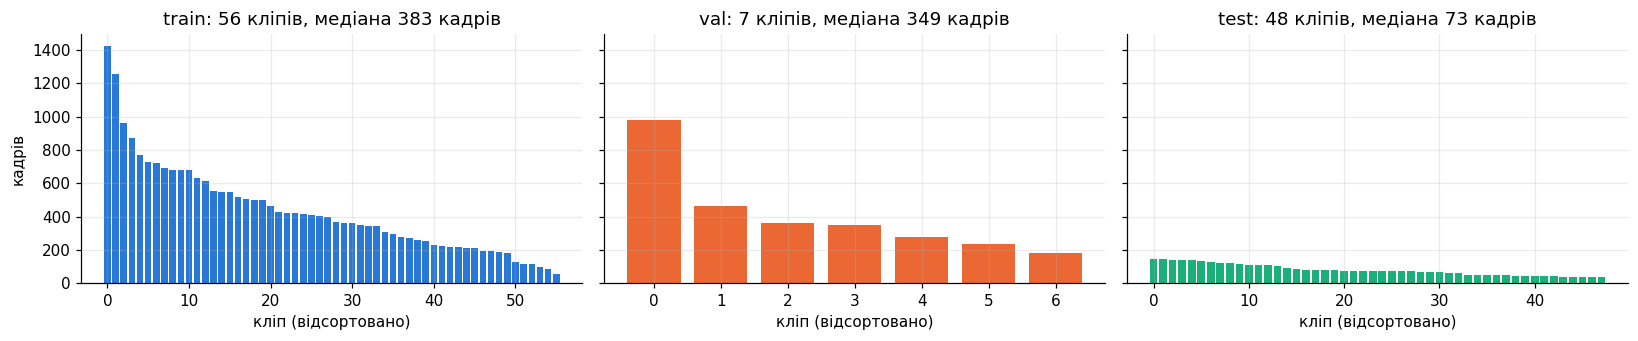

In [5]:
# кадрів на кліп — довжина послідовностей у кожному спліті
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for ax, (s, df) in zip(axes, [("train", IM[IM.split == "train"]), ("val", IM[IM.split == "val"]), ("test", TEST)]):
    n = df.groupby("video").size().sort_values(ascending=False)
    ax.bar(range(len(n)), n.values, color=SPLIT_C[s], width=0.8)
    ax.set_title(f"{s}: {len(n)} кліпів, медіана {int(n.median())} кадрів"); ax.set_xlabel("кліп (відсортовано)")
axes[0].set_ylabel("кадрів")
save("frames_per_clip")

## 2. Розподіл класів

split,train,val,train %,val %,clips_train,clips_val
name,,,,,,
person,328701,50312,29.73,44.08,55,7
bicycle,40255,6022,3.64,5.28,41,5
car,505301,31821,45.71,27.88,49,6
van,46940,6842,4.25,5.99,46,6
truck,30498,1359,2.76,1.19,39,5
tricycle,41349,5487,3.74,4.81,39,5
bus,9653,264,0.87,0.23,24,1
motor,102819,12025,9.30,10.54,50,6


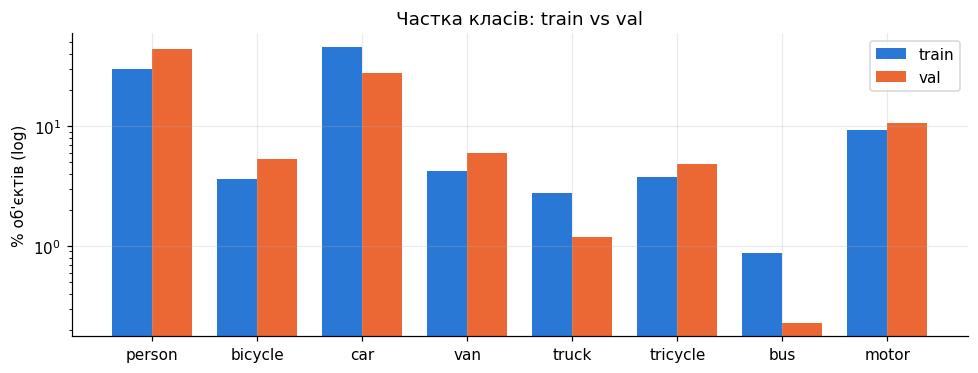

In [6]:
cnt = pd.crosstab(OBJ.name, OBJ.split)
share = (cnt / cnt.sum() * 100).round(2).add_suffix(" %")
clips_with = OBJ.groupby(["split", "name"]).video.nunique().unstack(0).add_prefix("clips_")
display(pd.concat([cnt, share, clips_with], axis=1))

fig, ax = plt.subplots(figsize=(9, 3.5))
xx = np.arange(len(NAMES)); bw = 0.38
for i, s in enumerate(["train", "val"]):
    ax.bar(xx + (i - 0.5) * bw, share[f"{s} %"].values, bw, label=s, color=SPLIT_C[s])
ax.set_xticks(xx, NAMES); ax.set_yscale("log"); ax.set_ylabel("% об'єктів (log)")
ax.set_title("Частка класів: train vs val"); ax.legend()
save("class_share")

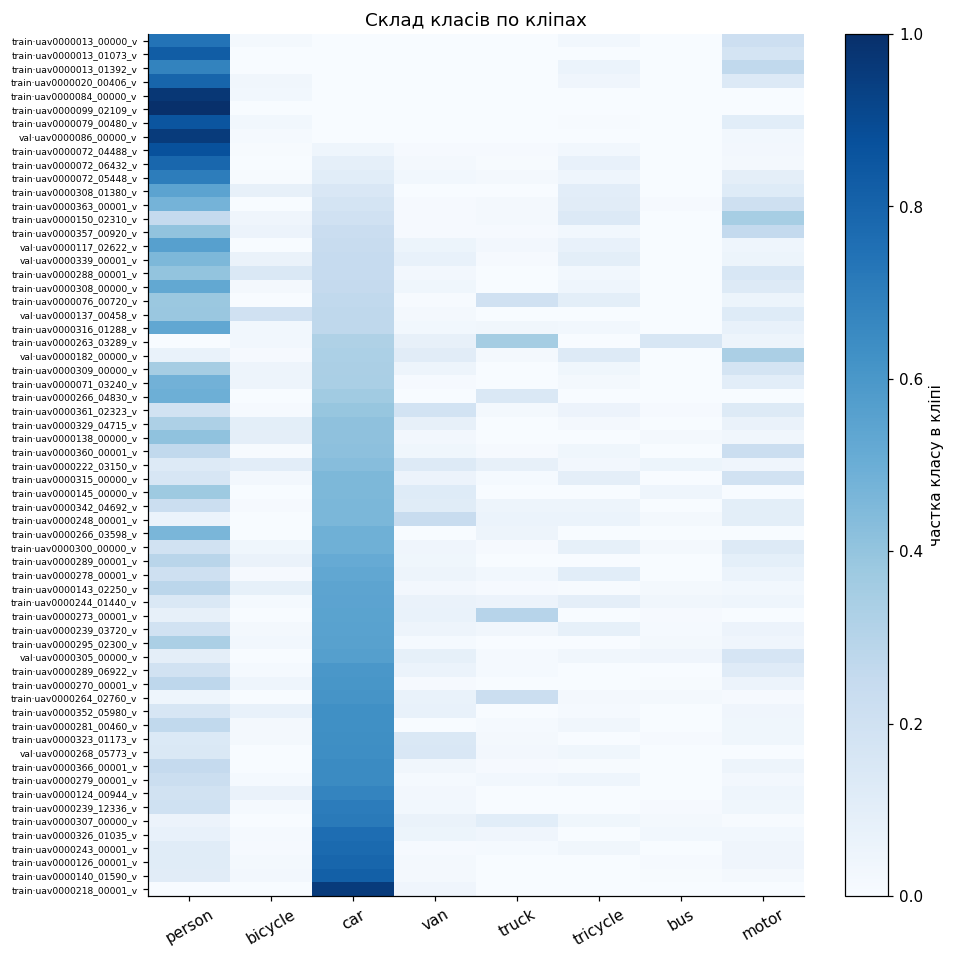

In [7]:
# частка класів усередині кожного кліпу — показує, що склад сцен сильно різниться між послідовностями
pc = pd.crosstab([OBJ.split, OBJ.video], OBJ.name, normalize="index")
pc = pc.sort_values("car")
fig, ax = plt.subplots(figsize=(9, max(6, len(pc) * 0.14)))
im_ = ax.imshow(pc.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(NAMES)), NAMES, rotation=30)
ax.set_yticks(range(len(pc)), [f"{s[0]}·{s[1]}" for s in pc.index], fontsize=6)
ax.grid(False); plt.colorbar(im_, label="частка класу в кліпі")
ax.set_title("Склад класів по кліпах")
save("class_by_clip")

## 3. Розміри об'єктів

COCO-метрика рахує small/medium/large в **оригінальних** пікселях (`area < 32²`, `< 96²`).
Але мережа бачить кадр **після ресайзу** до `imgsz` — тому окремо рахую ефективний розмір: `sqrt_area · imgsz / max(W, H)`.

In [8]:
OBJ["coco_size"] = pd.cut(OBJ.w * OBJ.h, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
display((pd.crosstab([OBJ.split, OBJ.name], OBJ.coco_size, normalize="index") * 100).round(1).unstack(0))
display(OBJ.groupby("split").sqrt_area.describe(percentiles=[.1, .25, .5, .75, .9]).round(1))

coco_size small       medium       large      
split     train   val  train   val train   val
name                                          
person     39.5  24.8   60.2  71.8   0.3   3.4
bicycle    24.4   2.9   74.1  85.6   1.5  11.5
car        16.4   9.4   64.5  70.7  19.1  19.9
van        21.5   5.8   62.7  71.4  15.9  22.8
truck       9.4   2.8   57.9  48.4  32.7  48.8
tricycle   21.1  18.7   66.1  58.9  12.8  22.4
bus         4.1   0.0   39.1  51.5  56.8  48.5
motor      30.4  40.4   68.2  55.1   1.4   4.5

,count,mean,std,min,10%,25%,50%,75%,90%,max
split,,,,,,,,,,
train,1105516.0,56.6,38.3,7.7,24.0,32.0,45.8,67.9,101.6,703.0
val,114132.0,61.9,43.9,9.8,26.1,35.5,52.4,73.2,99.3,399.5


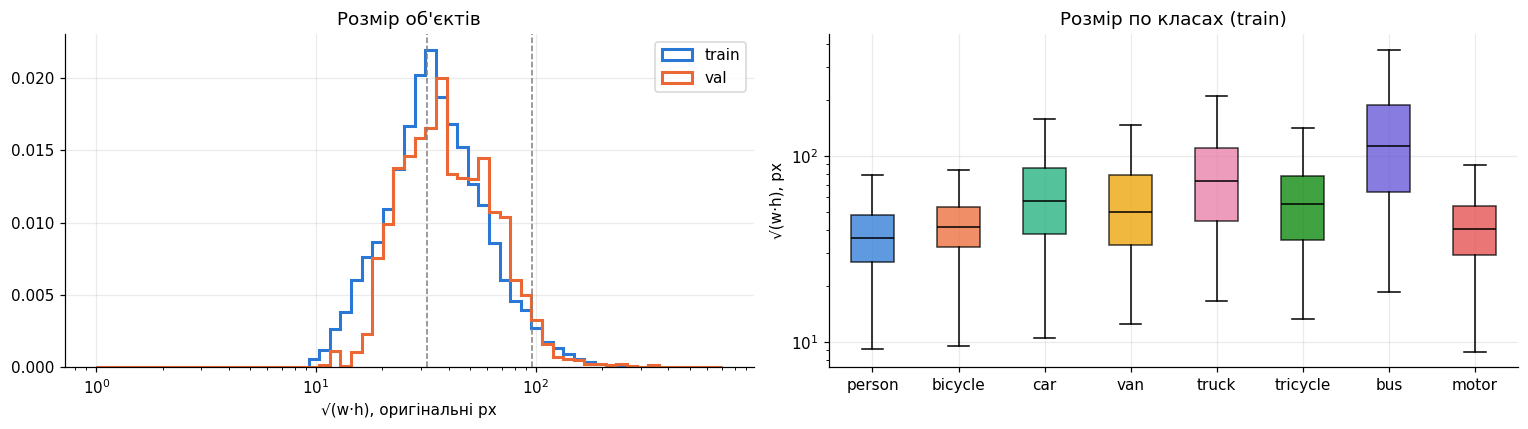

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.logspace(0, np.log10(OBJ.sqrt_area.max() + 1), 60)
for s in ["train", "val"]:
    axes[0].hist(OBJ.loc[OBJ.split == s, "sqrt_area"], bins=bins, density=True, histtype="step", lw=2,
                 color=SPLIT_C[s], label=s)
for t in (32, 96):
    axes[0].axvline(t, color="gray", ls="--", lw=1)
axes[0].set_xscale("log"); axes[0].set_xlabel("√(w·h), оригінальні px"); axes[0].set_title("Розмір об'єктів"); axes[0].legend()

_t = OBJ[OBJ.split == "train"].sample(frac=1, random_state=SEED)
samp = _t[_t.groupby("cls").cumcount() < 20000]                       # ≤20k на клас для швидкості
bp = axes[1].boxplot([samp.loc[samp.cls == k, "sqrt_area"] for k in range(8)],
                     showfliers=False, patch_artist=True, medianprops=dict(color="black"))
for p, c in zip(bp["boxes"], COLORS): p.set_facecolor(c); p.set_alpha(0.75)
axes[1].set_xticks(range(1, 9), NAMES); axes[1].set_yscale("log"); axes[1].set_ylabel("√(w·h), px"); axes[1].set_title("Розмір по класах (train)")
save("object_sizes")

,median_px,<8px %,<16px %,<32px %,min_side<4px %
imgsz,,,,,
640,15.3,9.7,53.6,89.2,1.7
960,22.9,1.8,23.5,73.2,0.7
1280,30.6,0.6,9.7,53.6,0.0
1536,36.7,0.2,4.8,39.4,0.0


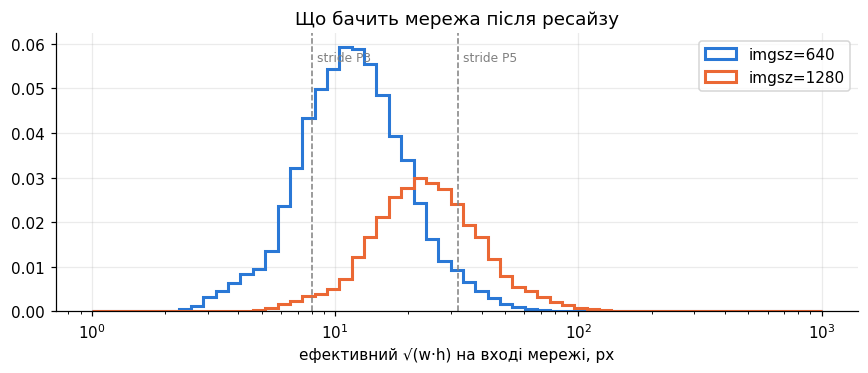

In [10]:
# ефективний розмір після letterbox-ресайзу до imgsz: яка частка об'єктів стає крихітною
rows = []
for imgsz in [640, 960, 1280, 1536]:
    eff = OBJ.sqrt_area * imgsz / OBJ.long_side
    eff_min = np.minimum(OBJ.w, OBJ.h) * imgsz / OBJ.long_side
    rows.append({"imgsz": imgsz, "median_px": eff.median().round(1),
                 "<8px %": (eff < 8).mean() * 100, "<16px %": (eff < 16).mean() * 100,
                 "<32px %": (eff < 32).mean() * 100, "min_side<4px %": (eff_min < 4).mean() * 100})
display(pd.DataFrame(rows).round(1).set_index("imgsz"))

fig, ax = plt.subplots(figsize=(8, 3.5))
for imgsz, c in zip([640, 1280], ["#2a78d6", "#eb6834"]):
    eff = OBJ.sqrt_area * imgsz / OBJ.long_side
    ax.hist(eff, bins=np.logspace(0, 3, 60), histtype="step", lw=2, color=c, density=True, label=f"imgsz={imgsz}")
for t, lab in [(8, "stride P3"), (32, "stride P5")]:
    ax.axvline(t, color="gray", ls="--", lw=1); ax.text(t * 1.05, ax.get_ylim()[1] * 0.9, lab, fontsize=8, color="gray")
ax.set_xscale("log"); ax.set_xlabel("ефективний √(w·h) на вході мережі, px"); ax.legend()
ax.set_title("Що бачить мережа після ресайзу")
save("effective_size")

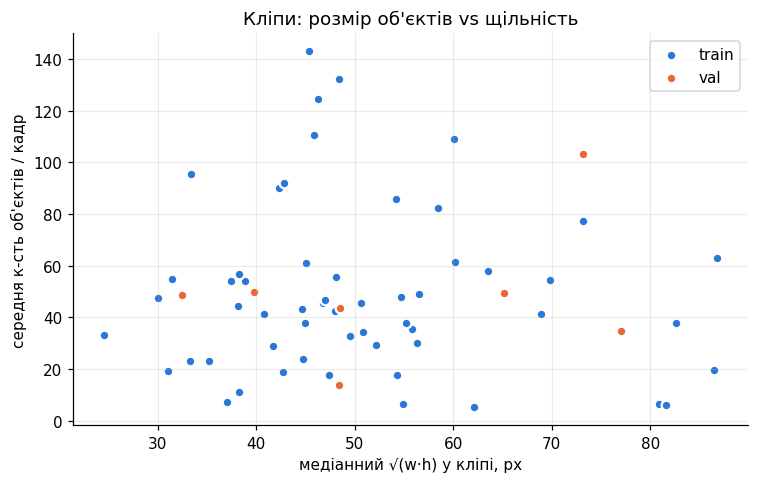

,split,video,med_size,res,mean_objs
22,train,uav0000239_12336_v,24.500000,1344,33.3
25,train,uav0000248_00001_v,30.000000,1344,47.5
27,train,uav0000264_02760_v,31.000000,1904,19.1
32,train,uav0000278_00001_v,31.500000,1360,55.0
59,val,uav0000182_00000_v,32.400002,1344,48.7
21,train,uav0000239_03720_v,33.299999,1344,23.0
33,train,uav0000279_00001_v,33.400002,1904,95.3
23,train,uav0000243_00001_v,35.200001,1344,22.9


In [11]:
# по кліпах: медіанний розмір vs щільність — видно різні висоти польоту дрона
pf = OBJ.groupby(["split", "video", "image_id"]).size().rename("n").reset_index()
clip = (OBJ.groupby(["split", "video"]).agg(med_size=("sqrt_area", "median"), res=("long_side", "first"))
        .join(pf.groupby(["split", "video"]).n.mean().rename("mean_objs")).reset_index())
fig, ax = plt.subplots(figsize=(7, 4.5))
for s in ["train", "val"]:
    d = clip[clip.split == s]
    ax.scatter(d.med_size, d.mean_objs, s=40, color=SPLIT_C[s], label=s, edgecolor="white", lw=1.5)
ax.set_xlabel("медіанний √(w·h) у кліпі, px"); ax.set_ylabel("середня к-сть об'єктів / кадр")
ax.set_title("Кліпи: розмір об'єктів vs щільність"); ax.legend()
save("clip_size_vs_density")
display(clip.sort_values("med_size").round(1).head(8))

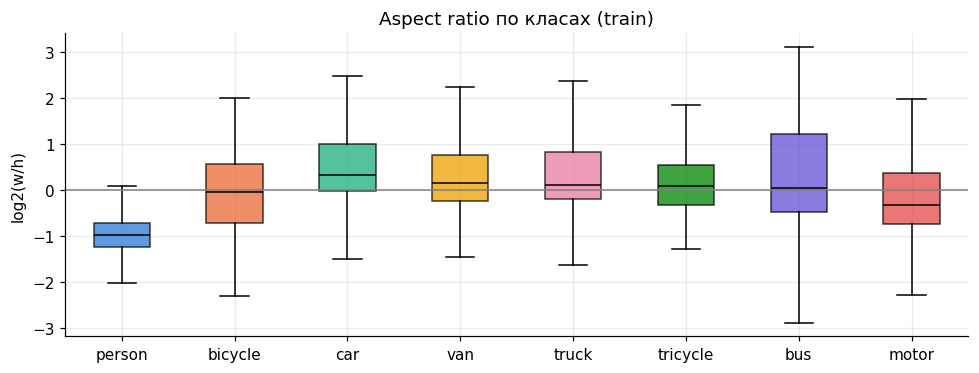

In [12]:
# співвідношення сторін по класах (log2 w/h): 0 = квадрат, <0 = витягнутий вертикально
fig, ax = plt.subplots(figsize=(9, 3.5))
bp = ax.boxplot([np.log2(samp.loc[samp.cls == k, "w"] / samp.loc[samp.cls == k, "h"]) for k in range(8)],
                showfliers=False, patch_artist=True, medianprops=dict(color="black"))
for p, c in zip(bp["boxes"], COLORS): p.set_facecolor(c); p.set_alpha(0.75)
ax.set_xticks(range(1, 9), NAMES); ax.axhline(0, color="gray", lw=1); ax.set_ylabel("log2(w/h)"); ax.set_title("Aspect ratio по класах (train)")
save("aspect_ratio")

## 4. Щільність сцен і перекриття GT

,count,mean,std,min,50%,90%,99%,max
split,,,,,,,,
train,24198.0,45.7,31.6,1.0,43.0,92.0,142.0,180.0
val,2846.0,40.1,26.8,8.0,37.0,81.0,112.6,116.0


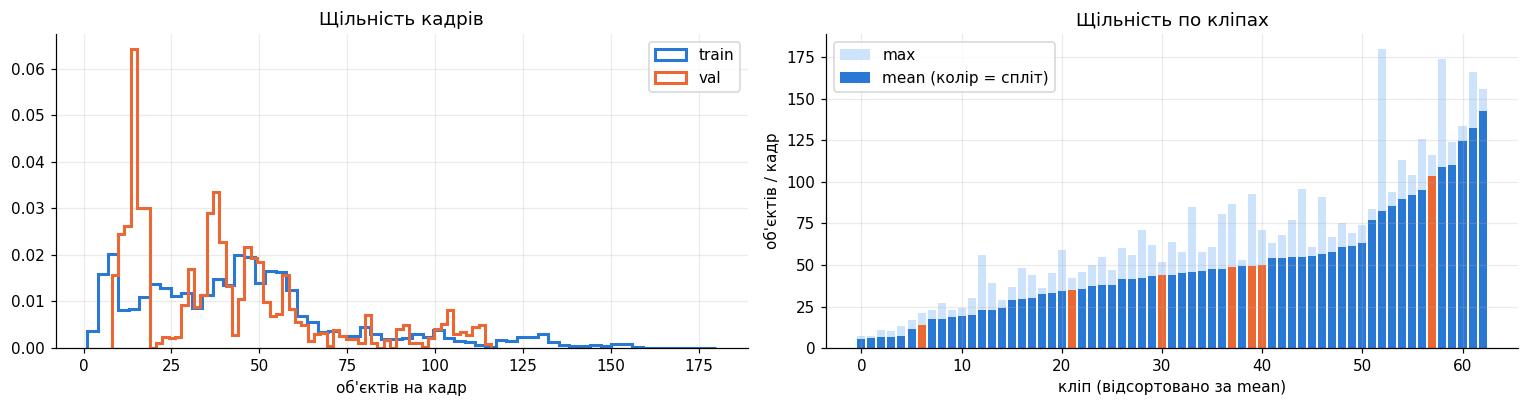

макс. об'єктів у кадрі: 180 → ліміт сабміту 500, дефолт Ultralytics max_det=300, RT-DETR 300 query


In [13]:
display(pf.groupby("split").n.describe(percentiles=[.5, .9, .99]).round(1))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for s in ["train", "val"]:
    axes[0].hist(pf.loc[pf.split == s, "n"], bins=60, density=True, histtype="step", lw=2, color=SPLIT_C[s], label=s)
axes[0].set_xlabel("об'єктів на кадр"); axes[0].legend(); axes[0].set_title("Щільність кадрів")

g = pf.groupby(["split", "video"]).n.agg(["mean", "max"]).reset_index().sort_values("mean")
axes[1].bar(range(len(g)), g["max"], color="#cde2fb", label="max")
axes[1].bar(range(len(g)), g["mean"], color=[SPLIT_C[s] for s in g.split], label="mean (колір = спліт)")
axes[1].set_xlabel("кліп (відсортовано за mean)"); axes[1].set_ylabel("об'єктів / кадр"); axes[1].legend()
axes[1].set_title("Щільність по кліпах")
save("density")
print("макс. об'єктів у кадрі:", pf.n.max(), "→ ліміт сабміту 500, дефолт Ultralytics max_det=300, RT-DETR 300 query")

In [14]:
def iou_matrix(a, b):
    # a: [n,4], b: [m,4] у форматі xyxy
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

OBJ[["x2", "y2"]] = OBJ[["x", "y"]].values + OBJ[["w", "h"]].values
# для кожного GT — max IoU з іншим GT того ж кадру (на вибірці кадрів)
sample_ids = OBJ.image_id.drop_duplicates().sample(min(3000, OBJ.image_id.nunique()), random_state=SEED)
recs = []
for iid, g in OBJ[OBJ.image_id.isin(sample_ids)].groupby("image_id"):
    b = g[["x", "y", "x2", "y2"]].values
    m = iou_matrix(b, b); np.fill_diagonal(m, 0)
    same = (g.cls.values[:, None] == g.cls.values[None, :])
    recs.append(pd.DataFrame({"name": g["name"].values, "max_iou_any": m.max(1) if len(g) > 1 else 0,
                              "max_iou_same": (m * same).max(1) if len(g) > 1 else 0}))
ov_df = pd.concat(recs)
tab = pd.DataFrame({f"IoU>{t} (same cls) %": ov_df.groupby("name").max_iou_same.apply(lambda v: (v > t).mean() * 100)
                    for t in (0.3, 0.5, 0.7)})
tab["IoU>0.3 (any cls) %"] = ov_df.groupby("name").max_iou_any.apply(lambda v: (v > 0.3).mean() * 100)
display(tab.round(2))
print("Частка GT, які NMS з порогом t може 'з'їсти' (є сусід того ж класу з IoU>t):",
      {t: round((ov_df.max_iou_same > t).mean() * 100, 2) for t in (0.5, 0.6, 0.7)})

,IoU>0.3 (same cls) %,IoU>0.5 (same cls) %,IoU>0.7 (same cls) %,IoU>0.3 (any cls) %
name,,,,
person,11.76,3.23,0.53,23.02
bicycle,3.76,0.31,0.08,36.49
car,6.20,0.69,0.09,6.96
van,0.07,0.00,0.00,5.56
truck,3.38,0.61,0.11,4.98
tricycle,2.14,0.27,0.08,10.43
bus,0.00,0.00,0.00,1.38
motor,2.32,0.55,0.14,25.85


Частка GT, які NMS з порогом t може 'з'їсти' (є сусід того ж класу з IoU>t): {0.5: np.float64(1.41), 0.6: np.float64(0.66), 0.7: np.float64(0.23)}


## 5. Occlusion / truncation (поля VisDrone)
`occlusion`: 0 — немає, 1 — часткова (1–50%), 2 — сильна (50–100%). `truncation`: 0 — ні, 1 — частково за кадром.

In [15]:
for col in ["occlusion", "truncation"]:
    if col in OBJ:
        display((pd.crosstab(OBJ.name, OBJ[col], normalize="index") * 100).round(1).add_prefix(f"{col}="))
if "occlusion" in OBJ:
    display(OBJ.groupby("occlusion").sqrt_area.median().rename("median √area").to_frame().T)

occlusion,occlusion=0,occlusion=1,occlusion=2
name,,,
person,53.0,40.9,6.1
bicycle,41.7,55.1,3.2
car,56.2,38.9,4.9
van,54.9,41.5,3.5
truck,34.6,49.8,15.6
tricycle,41.7,55.6,2.6
bus,56.6,41.3,2.0
motor,51.9,41.7,6.4


truncation,truncation=0,truncation=1
name,,
person,97.8,2.2
bicycle,99.0,1.0
car,94.2,5.8
van,94.3,5.7
truck,88.7,11.3
tricycle,95.8,4.2
bus,86.3,13.7
motor,96.7,3.3


occlusion,0,1,2
median √area,44.429718,47.864391,47.968739


## 6. Ignore-регіони

Ключове питання для препроцесингу: якщо замалювати ignore-регіон сірим, чи не сховаємо ми під ним **розмічені** GT?
Для кожного GT рахую, яка частка його площі лежить усередині ignore-прямокутника.

In [16]:
print("category_id ignore-записів у json (кожен регіон має копію на кожен клас):")
display(IGN_ALL.category_id.value_counts().sort_index().to_frame().T)
if "orig_category_id" in IGN:
    print("orig_category_id у ignore (0 = ignored region, 11 = others):")
    display(IGN.groupby("split").orig_category_id.value_counts().unstack(0))

# площа кадру, покрита ignore (растеризація маски в 1/8 роздільної здатності)
cov = []
for iid, g in IGN.groupby("image_id"):
    W, H = g.width.iat[0], g.height.iat[0]
    m = np.zeros((H // 8 + 1, W // 8 + 1), np.uint8)
    for x, y, w, h in g[["x", "y", "w", "h"]].values / 8:
        m[int(y):int(np.ceil(y + h)), int(x):int(np.ceil(x + w))] = 1
    cov.append((iid, g.split.iat[0], g.video.iat[0], len(g), m.mean()))
cov = pd.DataFrame(cov, columns=["image_id", "split", "video", "n_regions", "covered"])
display(cov.groupby("split")[["n_regions", "covered"]].describe(percentiles=[.5, .9]).round(3).T)

# частка площі GT усередині ignore
IGN[["x2", "y2"]] = IGN[["x", "y"]].values + IGN[["w", "h"]].values
idx_parts, val_parts = [], []
ign_by = dict(tuple(IGN.groupby("image_id")))
for iid, g in OBJ[OBJ.image_id.isin(ign_by)].groupby("image_id"):
    a = g[["x", "y", "x2", "y2"]].values; b = ign_by[iid][["x", "y", "x2", "y2"]].values
    iw = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    ih = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    idx_parts.append(g.index.values); val_parts.append((iw * ih / (g.w.values * g.h.values)[:, None]).max(1))
OBJ["in_ignore"] = 0.0
if idx_parts:
    OBJ.loc[np.concatenate(idx_parts), "in_ignore"] = np.concatenate(val_parts)
print("GT, що перетинаються з ignore:", {t: f"{(OBJ.in_ignore > t).mean() * 100:.2f}%" for t in (0, 0.5, 0.9)})
display((OBJ[OBJ.in_ignore > 0.5].groupby("name").size() / OBJ.groupby("name").size() * 100).round(2)
        .rename("% GT класу >50% під ignore").to_frame().T)

category_id ignore-записів у json (кожен регіон має копію на кожен клас):


category_id,1,2,3,4,5,6,7,8
count,67838,67838,67838,67838,67838,67838,67838,67838


orig_category_id у ignore (0 = ignored region, 11 = others):


split,train,val
orig_category_id,,
0,62369,3994
11,1474,1


split                train       val
n_regions count  18090.000  1434.000
          mean       3.529     2.786
          std        3.267     1.253
          min        1.000     1.000
          50%        2.000     3.000
          90%        8.000     5.000
          max       22.000     7.000
covered   count  18090.000  1434.000
          mean       0.034     0.034
          std        0.044     0.030
          min        0.001     0.002
          50%        0.018     0.017
          90%        0.086     0.085
          max        0.389     0.105

GT, що перетинаються з ignore: {0: '3.49%', 0.5: '1.06%', 0.9: '0.68%'}


name,person,bicycle,car,van,truck,tricycle,bus,motor
% GT класу >50% під ignore,1.39,1.69,0.89,1.1,0.56,1.45,0.37,0.56


## 7. Перевірка конвертації (YOLO txt ↔ COCO json) і візуалізація GT

In [17]:
# читалки з hw2lib — ті самі функції використовує побудова датасету, тож перевіряємо саме їх
def read_yolo(split, video, stem, W, H):     # -> cls, x, y, w, h (px, top-left)
    return _read_yolo_px(ROOT / split / "labels" / video / f"{stem}.txt", W, H)

def read_ignore(split, video, stem, W, H):   # -> x, y, w, h (px)
    return _read_ignore_px(ROOT / split / "ignore" / video / f"{stem}.txt", W, H)

_t = IM.sample(frac=1, random_state=SEED); chk = _t[_t.groupby("split").cumcount() < 400]
obj_by = dict(tuple(OBJ[OBJ.image_id.isin(chk.image_id)].groupby("image_id"))); bad = []
for r in chk.itertuples():
    stem = Path(r.file_name).stem
    y = read_yolo(r.split, r.video, stem, r.width, r.height)
    c = obj_by.get(r.image_id, pd.DataFrame(columns=["cls", "x", "y", "w", "h"]))
    c = c[["cls", "x", "y", "w", "h"]].values.astype(float)
    ig = read_ignore(r.split, r.video, stem, r.width, r.height)
    n_ign = len(ign_by[r.image_id]) if r.image_id in ign_by else 0
    if len(y) != len(c) or len(ig) != n_ign:
        bad.append((r.file_name, "count", len(y), len(c), len(ig), n_ign)); continue
    if len(y):
        # кожному боксу з txt шукаємо найближчий бокс того ж класу з json (і навпаки)
        d = np.abs(y[:, None, 1:] - c[None, :, 1:]).max(-1) + 1e6 * (y[:, None, 0] != c[None, :, 0])
        err = max(d.min(1).max(), d.min(0).max())
        if err > 2.0: bad.append((r.file_name, "coords", round(float(err), 2)))
print(f"перевірено {len(chk)} кадрів, розбіжностей: {len(bad)}"); print(bad[:5])

перевірено 800 кадрів, розбіжностей: 0
[]


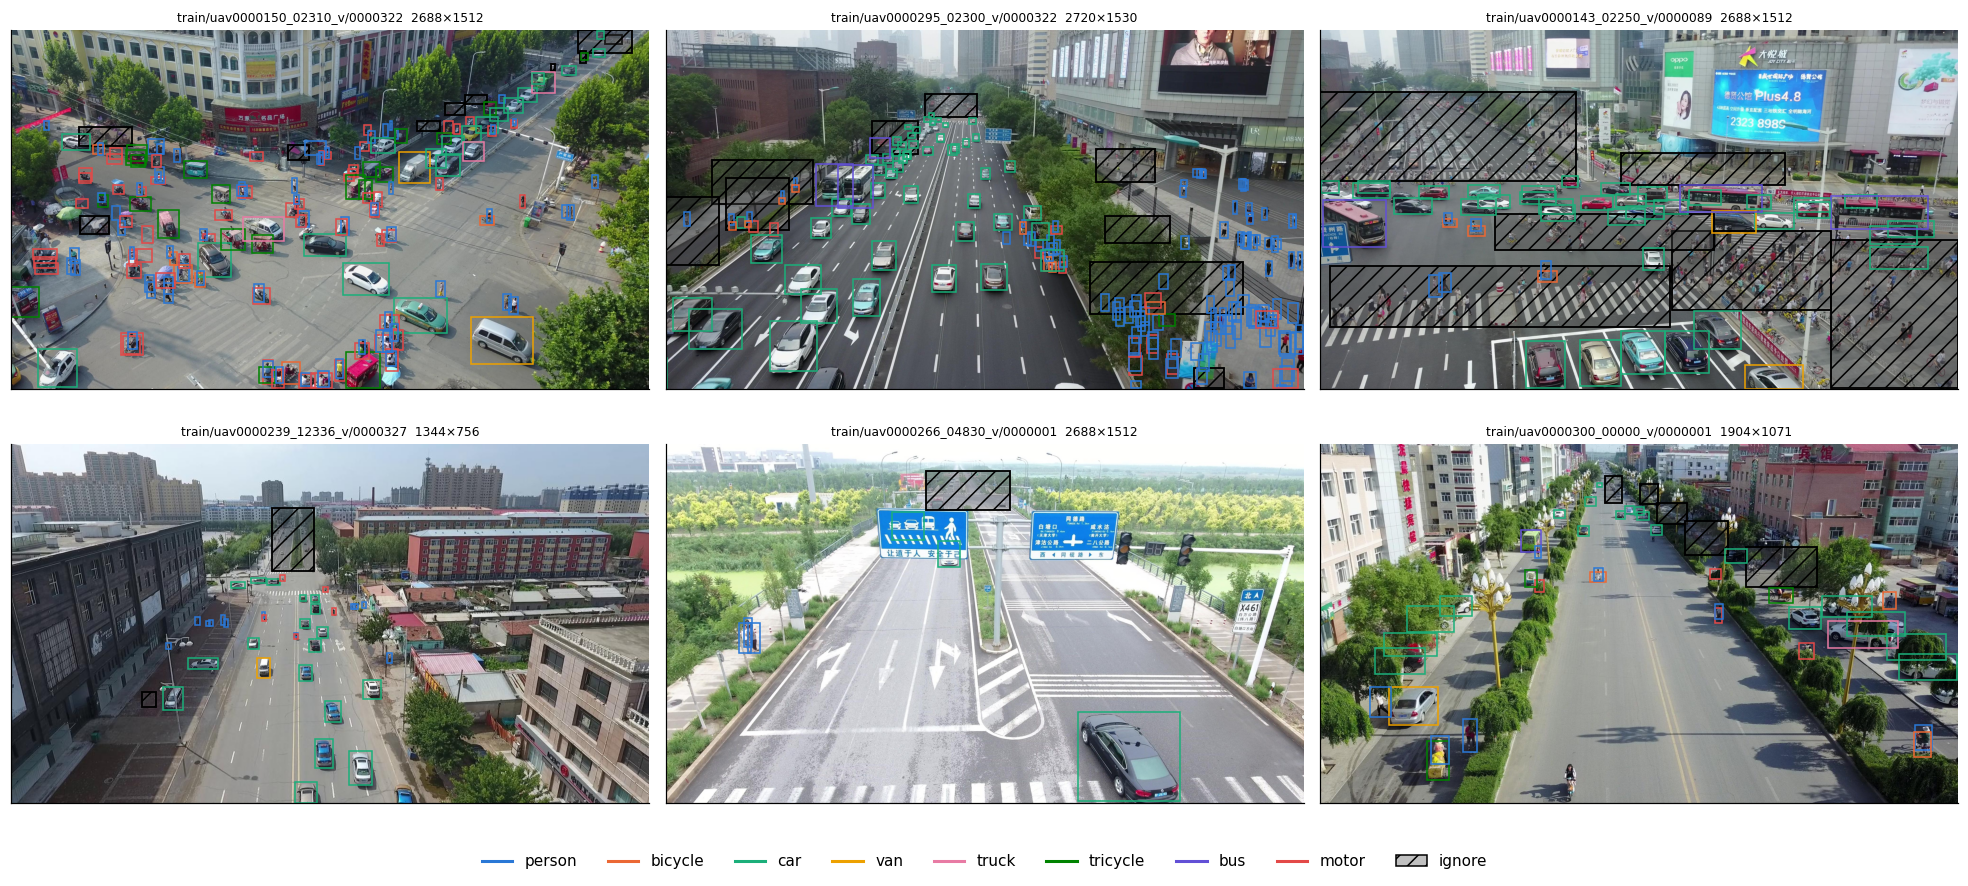

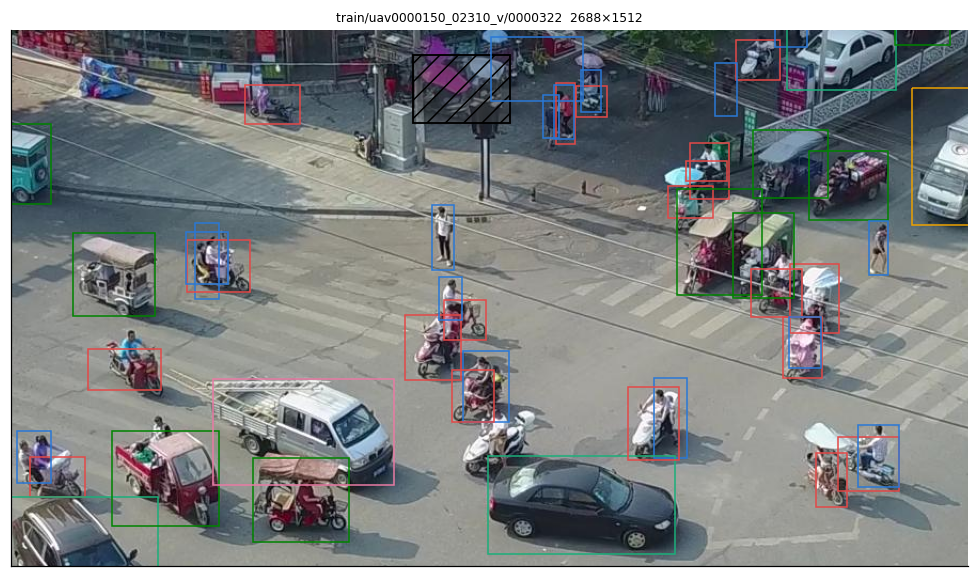

In [18]:
def draw(ax, row, crop=None):
    stem = Path(row.file_name).stem
    img = cv2.cvtColor(cv2.imread(str(ROOT / row.split / "images" / row.video / f"{stem}.jpg")), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    for x, y, w, h in read_ignore(row.split, row.video, stem, row.width, row.height):   # ignore — сіра штриховка
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=True, fc=(0.3, 0.3, 0.3, 0.35), ec="black", lw=1.2, hatch="//"))
    for k, x, y, w, h in read_yolo(row.split, row.video, stem, row.width, row.height):  # GT з YOLO txt
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec=COLORS[int(k)], lw=1))
    if crop: ax.set_xlim(crop[0], crop[2]); ax.set_ylim(crop[3], crop[1])
    ax.set_title(f"{row.split}/{row.video}/{stem}  {row.width}×{row.height}", fontsize=8)

# 6 різних кліпів: найщільніші, з найбільшим ignore, з найменшими об'єктами
dense = pf.sort_values("n").groupby("video").tail(1).sort_values("n").image_id.values[-2:]
most_ign = cov.sort_values("covered").image_id.values[-2:] if len(cov) else []
tiny = OBJ.groupby("image_id").sqrt_area.median().sort_values().index.values[:2]
pick = (IM.set_index("image_id").loc[list(dict.fromkeys([*dense, *most_ign, *tiny]))].reset_index()
        .drop_duplicates("video").head(6))                     # по одному кадру з кліпу
extra = IM[~IM.video.isin(pick.video)].drop_duplicates("video").sample(frac=1, random_state=SEED)
pick = pd.concat([pick, extra]).head(6)                       # добираємо до 6 різних кліпів
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax in axes.ravel(): ax.set_visible(False)
for ax, row in zip(axes.ravel(), pick.itertuples()): ax.set_visible(True); draw(ax, row)
handles = [plt.Line2D([], [], color=c, lw=2, label=n) for n, c in zip(NAMES, COLORS)]
handles.append(plt.Rectangle((0, 0), 1, 1, fc=(0.3, 0.3, 0.3, 0.35), ec="black", hatch="//", label="ignore"))
fig.legend(handles=handles, loc="lower center", ncol=9, frameon=False, bbox_to_anchor=(0.5, -0.03))
save("gt_samples")

# зум у найщільніший кадр — щоб було видно дрібні бокси
row = pick.iloc[0]
g = OBJ[OBJ.image_id == row.image_id]; cx, cy = g.x.median(), g.y.median(); s = row.width / 6
fig, ax = plt.subplots(figsize=(9, 5.5)); draw(ax, row, crop=(cx - s, cy - s * 0.56, cx + s, cy + s * 0.56))
save("gt_zoom")

## 8. Часова кореляція кадрів

Сусідні кадри майже ідентичні → проріджуємо train. Щоб обґрунтувати крок, для кожного трека (`track_id`) рахую IoU бокса між кадрами *t* і *t+k*.
Чим ближче IoU до 1, тим менше нової інформації дає кадр *t+k*.

,median_IoU,median_IoU_small,IoU_gt_0_5_pct,tracks_alive_pct
k,,,,
1,0.895,0.870,95.217,99.541
2,0.806,0.768,85.112,99.099
4,0.655,0.596,65.891,98.219
8,0.432,0.349,44.343,96.479
16,0.171,0.076,28.937,93.161
32,0.000,0.000,19.871,86.968


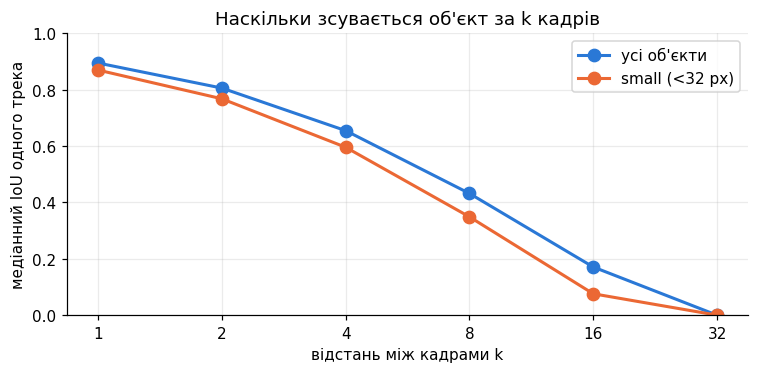

In [19]:
tr = OBJ.loc[OBJ.track_id >= 0, ["track_id", "frame_id", "x", "y", "x2", "y2", "sqrt_area"]].copy()
tr.insert(0, "vid", pd.factorize(OBJ.loc[tr.index, "video"])[0].astype(np.int16))
tr["frame_id"] = tr.frame_id.astype(np.int32)
last = tr.groupby("vid").frame_id.transform("max")
ks = [1, 2, 4, 8, 16, 32]; rows = []
for k in ks:
    nxt = tr.assign(frame_id=tr.frame_id - k)
    m = tr.merge(nxt, on=["vid", "track_id", "frame_id"], suffixes=("", "_k"))
    ix = np.clip(np.minimum(m.x2, m.x2_k) - np.maximum(m.x, m.x_k), 0, None)
    iy = np.clip(np.minimum(m.y2, m.y2_k) - np.maximum(m.y, m.y_k), 0, None)
    inter = ix * iy
    iou = inter / ((m.x2 - m.x) * (m.y2 - m.y) + (m.x2_k - m.x_k) * (m.y2_k - m.y_k) - inter)
    small = m.sqrt_area < 32
    # частка об'єктів кадру t, що ще присутні в t+k
    alive = len(m) / int((tr.frame_id + k <= last).sum())
    rows.append(dict(k=k, median_IoU=iou.median(), median_IoU_small=iou[small].median(),
                     IoU_gt_0_5_pct=(iou > 0.5).mean() * 100, tracks_alive_pct=alive * 100))
    del m, nxt
tc = pd.DataFrame(rows).set_index("k").round(3); display(tc)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tc.index, tc.median_IoU, "-o", color="#2a78d6", lw=2, ms=8, label="усі об'єкти")
ax.plot(tc.index, tc.median_IoU_small, "-o", color="#eb6834", lw=2, ms=8, label="small (<32 px)")
ax.set_xscale("log", base=2); ax.set_xticks(ks, ks); ax.set_ylim(0, 1)
ax.set_xlabel("відстань між кадрами k"); ax.set_ylabel("медіанний IoU одного трека"); ax.legend()
ax.set_title("Наскільки зсувається об'єкт за k кадрів")
save("temporal_iou")

## 9. Сплітинг по послідовностях

In [20]:
tv = set(IM[IM.split == "train"].video) & set(IM[IM.split == "val"].video)
print("спільні кліпи train∩val:", tv or "немає ✓")

# 5 фолдів по кліпах (кадри одного відео завжди в одному фолді); жадібно вирівнюємо к-сть кадрів
tr_im = IM[IM.split == "train"].reset_index(drop=True)
n_frames = tr_im.groupby("video").size().sort_values(ascending=False)
load = np.zeros(5, int); fold_of = {}
for v, n in n_frames.items():
    f = int(load.argmin()); fold_of[v] = f; load[f] += n
fold_of = pd.Series(fold_of, name="fold"); fold_of.index.name = "video"
tr_im["fold"] = tr_im.video.map(fold_of)
o_tr = OBJ[OBJ.split == "train"].assign(fold=lambda d: d.video.map(fold_of))
fs = pd.concat([tr_im.groupby("fold").agg(clips=("video", "nunique"), frames=("image_id", "size")),
                o_tr.groupby("fold").agg(objects=("cls", "size"), median_size=("sqrt_area", "median")),
                (pd.crosstab(o_tr.fold, o_tr.name, normalize="index") * 100).round(1)], axis=1)
display(fs)
Path("../results").mkdir(exist_ok=True)
fold_of.to_csv("../results/folds_by_clip.csv")
print("збережено code/results/folds_by_clip.csv")

спільні кліпи train∩val: немає ✓


,clips,frames,objects,median_size,person,bicycle,car,van,truck,tricycle,bus,motor
fold,,,,,,,,,,,,
0,10,4830,181271,47.434166,35.9,7.6,38.4,4.5,0.9,2.0,0.4,10.3
1,11,4844,142834,52.249401,32.4,4.2,44.5,4.4,2.6,3.7,1.9,6.4
2,12,4876,295426,45.376205,28.8,3.5,48.2,2.8,1.9,3.6,0.5,10.9
3,11,4787,259822,45.825756,28.5,2.6,49.2,4.9,4.9,3.2,1.2,5.4
4,12,4864,226163,41.412560,25.8,1.5,45.0,5.2,3.0,5.9,0.7,12.7


збережено code/results/folds_by_clip.csv


## 10. Якорі: k-means по датасету vs дефолт torchvision

Як у YOLOv2: k-means по (w, h) з відстанню `1 − IoU`. Покриття = частка GT, для яких знайдеться якір з shape-IoU ≥ 0.5
(приблизно поріг позитивного матчингу в RetinaNet/RPN). Рахую в координатах входу мережі (після ресайзу).

In [21]:
def shape_iou(wh, anc):
    inter = np.minimum(wh[:, None, 0], anc[None, :, 0]) * np.minimum(wh[:, None, 1], anc[None, :, 1])
    return inter / (wh.prod(1)[:, None] + anc.prod(1)[None, :] - inter)

def kmeans_iou(wh, k, iters=100, seed=SEED):
    rng = np.random.default_rng(seed); c = wh[rng.choice(len(wh), k, replace=False)]
    for _ in range(iters):
        a = shape_iou(wh, c).argmax(1)
        new = np.array([np.median(wh[a == j], 0) if (a == j).any() else c[j] for j in range(k)])
        if np.allclose(new, c): break
        c = new
    return c[np.argsort(c.prod(1))]

def anchors(sizes, ratios=(0.5, 1.0, 2.0)):            # ratio = h/w, як у torchvision
    return np.array([[s / np.sqrt(r), s * np.sqrt(r)] for s in sizes for r in ratios])

rows, KM = [], {}
for imgsz in [640, 1280]:
    sub = OBJ[OBJ.split == "train"].sample(min(150_000, (OBJ.split == "train").sum()), random_state=SEED)
    wh = (sub[["w", "h"]].values * (imgsz / sub.long_side.values)[:, None]).clip(1)
    KM[imgsz] = kmeans_iou(wh, 9)
    cands = {
        "torchvision FasterRCNN (32..512)": anchors([32, 64, 128, 256, 512]),
        "torchvision RetinaNet (32..512 ×3 scales)": anchors([s * 2 ** (i / 3) for s in [32, 64, 128, 256, 512] for i in range(3)]),
        "shrunk RetinaNet (8..128 ×3 scales)": anchors([s * 2 ** (i / 3) for s in [8, 16, 32, 64, 128] for i in range(3)]),
        "k-means 9": KM[imgsz],
    }
    for n, a in cands.items():
        best = shape_iou(wh, a).max(1)
        rows.append(dict(imgsz=imgsz, anchors=n, n_anchors=len(a), mean_best_IoU=best.mean(),
                         coverage_IoU_0_5=(best >= 0.5).mean() * 100,
                         coverage_small=(best[np.sqrt(wh.prod(1)) < 32] >= 0.5).mean() * 100))
display(pd.DataFrame(rows).round(3).set_index(["imgsz", "anchors"]))
for k, v in KM.items(): print(f"k-means anchors (w×h) @ {k}:", [f"{w:.0f}×{h:.0f}" for w, h in v])

n_anchors  mean_best_IoU  \
imgsz anchors                                                               
640   torchvision FasterRCNN (32..512)                  15          0.310   
      torchvision RetinaNet (32..512 ×3 scales)         45          0.323   
      shrunk RetinaNet (8..128 ×3 scales)               45          0.810   
      k-means 9                                          9          0.729   
1280  torchvision FasterRCNN (32..512)                  15          0.588   
      torchvision RetinaNet (32..512 ×3 scales)         45          0.647   
      shrunk RetinaNet (8..128 ×3 scales)               45          0.827   
      k-means 9                                          9          0.729   

                                                 coverage_IoU_0_5  \
imgsz anchors                                                       
640   torchvision FasterRCNN (32..512)                     23.137   
      torchvision RetinaNet (32..512 ×3 scales)            23.139   
      shrunk RetinaNet (8..128 ×3 scales)                  97.697   
      k-means 9                                            95.427   
1280  torchvision FasterRCNN (32..512)                     71.811   
      torchvision RetinaNet (32..512 ×3 scales)            71.817   
      shrunk RetinaNet (8..128 ×3 scales)                  99.842   
      k-means 9                                            95.427   

                                                 coverage_small  
imgsz anchors                                                    
640   torchvision FasterRCNN (32..512)                   13.788  
      torchvision RetinaNet (32..512 ×3 scales)          13.788  
      shrunk RetinaNet (8..128 ×3 scales)                97.437  
      k-means 9                                          97.190  
1280  torchvision FasterRCNN (32..512)                   48.147  
      torchvision RetinaNet (32..512 ×3 scales)          48.147  
      shrunk RetinaNet (8..128 ×3 scales)                99.796  
      k-means 9                                          95.825

k-means anchors (w×h) @ 640: ['6×8', '11×10', '8×15', '20×10', '16×15', '12×23', '32×17', '22×28', '52×37']
k-means anchors (w×h) @ 1280: ['11×16', '22×20', '15×31', '39×20', '32×31', '24×46', '63×34', '44×56', '104×73']


## 11. Побудова датасету для Ultralytics (`hw2lib.data.build_split`)

* **train**: кожен `train_step`-й кадр (§8). Ignore-регіони замальовуються сірим 114 (той самий колір, що паддінг у letterbox/mosaic),
  GT, що на >50% під маскою, видаляються з лейблів (§6). Кадри зменшуються до довшої сторони `train_max_side` — лейбли нормалізовані,
  тож не змінюються, а декодування JPEG на 4 CPU Kaggle стає в рази швидшим.
* **val**: без змін (симлінки на оригінали). Ignore враховує `hw2lib.evaluate.Evaluator` через `iscrowd=1` — як на лідерборді.
* Той самий код запускається на Kaggle (етап 2); локально — лише перевірка, результат іде в `hw2/build/` (поза git).

In [22]:
RUN_BUILD = False                     # True — зібрати локально для перевірки
OUT = BUILD / f"yolo_step{PROTOCOL['train_step']}"
print(PROTOCOL)
if RUN_BUILD:
    if OUT.exists(): shutil.rmtree(OUT)
    build_split(ROOT, OUT, "train", PROTOCOL["train_step"], mask=True, max_side=PROTOCOL["train_max_side"])
    build_split(ROOT, OUT, "val", PROTOCOL["val_step"], mask=False)
    print(write_data_yaml(OUT).read_text())

{'train_step': 4, 'val_step': 2, 'train_max_side': 1600, 'imgsz': 1024, 'epochs': 10, 'seed': 0, 'conf': 0.001, 'max_det': 500}


In [23]:
# візуальна перевірка зібраного train-кадру з маскою
if RUN_BUILD and len(cov):
    IMi = IM.set_index("image_id"); p = None
    for iid in cov.query("split == 'train'").sort_values("covered", ascending=False).image_id:
        r = IMi.loc[iid]; stem = Path(r.file_name).stem
        if (OUT / "train" / "images" / r.video / f"{stem}.jpg").exists():
            p = OUT / "train" / "images" / r.video / f"{stem}.jpg"; break
    if p is not None:
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
        fig, ax = plt.subplots(figsize=(12, 7)); ax.imshow(img); ax.grid(False); ax.axis("off")
        for k, x, y, w, h in _read_yolo_px(OUT / "train" / "labels" / r.video / f"{stem}.txt", W, H):
            ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec=COLORS[int(k)], lw=1))
        ax.set_title(f"зібраний train-кадр (маска + ресайз до {W}×{H}): {r.video}/{stem}")
        save("built_masked_sample")

## Висновки → рішення

| Спостереження (§) | Число | Рішення |
|---|---|---|
| Частка об'єктів < 16 px на вході при imgsz 640 / 1280 (§3) |  |  |
| Роздільна здатність train vs test (§1) |  |  |
| Макс. об'єктів у кадрі; GT з сусідом IoU > 0.6 (§4) |  |  |
| GT > 50 % під ignore (§6) |  |  |
| Медіанний IoU трека при k = 4 (§8) |  |  |
| Покриття якорів: дефолт vs k-means (§10) |  |  |
| Рідкісні класи та кліпи, де вони є (§2) |  |  |